## Parameters vs Hyperparameters

Parameters	                          Hyperparameters

Learned during training	           Set before or during model selection

Coefficients and intercept	       Regularization strength, tree depth

Determined by fit()	               Selected through tuning

For example, in Ridge Regression:
- Coefficients are model parameters.
- alpha is a hyperparameter.

Our goal is to find hyperparameters that give good performance on unseen data

## 2. What is GridSearchCV?
GridSearchCV tries every combination of hyperparameter values you provide and evaluates each combination using cross-validation.

In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split

X, y = make_regression(
    n_samples=500,
    n_features=15,
    n_informative=8,
    noise=25,
    random_state=42
)

X = pd.DataFrame(
    X,
    columns=[f"Feature_{i}" for i in range(15)]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (400, 15)
Testing: (100, 15)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

In [3]:
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV RMSE:", np.sqrt(-grid_search.best_score_))

Best parameters: {'model__alpha': 1}
Best CV RMSE: 26.982243738272423


GridSearchCV automatically:
1. Tries each specified alpha.
2. Performs five-fold cross-validation.
3. Calculates the average validation score.
4. Selects the best configuration.
5. Refits the best estimator on the full training data by default.

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

MAE: 19.51801547439858
RMSE: 24.78616521478067
R2: 0.9813659015318654


The test set is used for final evaluation, not for choosing alpha.

## 3. What is RandomizedSearchCV?
GridSearchCV tries every combination in the supplied grid.

But imagine you have many hyperparameters and hundreds of possible values. The number of combinations can become very large.

RandomizedSearchCV samples a fixed number of combinations instead.

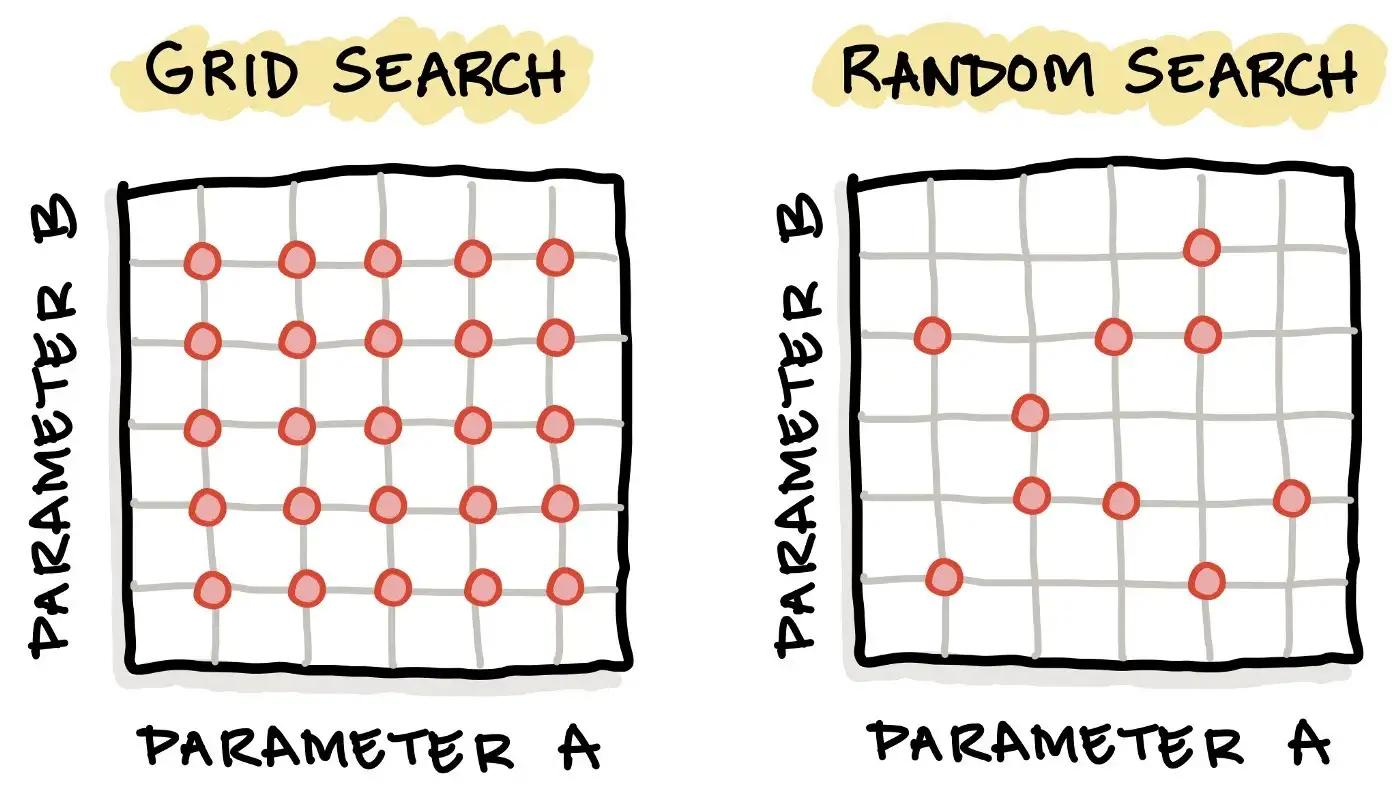

In [5]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

param_distributions = {
    "model__alpha": loguniform(0.001, 1000)
}

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    cv=cv,
    scoring="neg_mean_squared_error",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best parameters:", random_search.best_params_)
print("Best CV RMSE:", np.sqrt(-random_search.best_score_))

Best parameters: {'model__alpha': np.float64(1.40779231399724)}
Best CV RMSE: 26.982233135050564


In [6]:
cv_results = pd.DataFrame(grid_search.cv_results_)

print(
    cv_results[
        ["param_model__alpha", "mean_test_score", "rank_test_score"]
    ]
)

   param_model__alpha  mean_test_score  rank_test_score
0                0.01      -728.622002                3
1                0.10      -728.534985                2
2                1.00      -728.041477                1
3               10.00      -758.029690                4
4              100.00     -2872.576385                5


# 🔍 Hyperparameter Tuning: GridSearchCV vs. RandomizedSearchCV

When optimizing a model, we must find the best **Hyperparameters** (settings configured before training, like `max_depth` or `n_estimators`). Instead of manual guessing, Scikit-learn automates this using two strategies paired with **Cross-Validation (CV)** to ensure stable, reliable scores.

---

### 📊 Quick Comparison

| Feature | `GridSearchCV` | `RandomizedSearchCV` |
| :--- | :--- | :--- |
| **Search Strategy** | Exhaustive over supplied grid | Random sampling |
| **Number of Trials** | All possible combinations | Fixed budget via `n_iter` |
| **Computational Cost** | High (scales exponentially) | Low & completely controllable |
| **Best For** | Small search spaces (< 3 variables) | Large search spaces (wide ranges) |

---

### 💡 Core Concepts & Strategy

* **GridSearchCV (The Systematic Surveyor)**
  * Evaluates *every single mathematical combination* of the parameters you provide.
  * **Pros:** Guaranteed to find the absolute best combination within your specified grid.
  * **Cons:** Extremely slow. Adding one more parameter can multiply training time by hours.

* **RandomizedSearchCV (The Smart Explorer)**
  * Randomly selects a fixed number of combinations (`n_iter`) from the parameter distribution.
  * **Pros:** Blazing fast. You control the exact timeframe by capping the number of iterations.
  * **Cons:** Might skip the absolute optimal configuration if `n_iter` is set too low.

---

### ⚠️ The Golden Rule of Optimization

> **"Neither guarantees the absolute best possible model in the world. They can only search within the boundaries you provide."**

If the perfect value for a setting is `100`, but your input list only tests `[10, 20, 30]`, both algorithms will completely miss it. Your optimization is only as good as the search space you design.

---

### 🗺️ The Treasure Hunt Analogy

Imagine looking for buried treasure in a 10x10 km grid:
* **GridSearchCV** digs up every single square meter systematically. It takes forever, but guarantees success.
* **RandomizedSearchCV** throws 20 darts at the map and only digs in those 20 spots. It is incredibly fast and usually gets close enough to the prize without exhausting your computational power.


Important professional practices
- Tune hyperparameters using training data and cross-validation.
- Keep a separate test set for final evaluation.
- Use pipelines to prevent preprocessing leakage.
- Avoid enormous search spaces without a reason.
- Consider computational cost.
- Use time-series or group-aware cross-validation when the data requires it.